# **Zespół:**
Michał Sadrzak (s30679), Maciej Zieliński (s30755), Szymon Zyśk (s30690), Dariusz Lasota (s31771).

## **Motywacja biznesowa**

Firma zarządzająca flotą samochodową chce porównywać pojazdy pod względem zużycia paliwa i emisji CO₂. Analiza może wspierać wybór aut do floty, wstępne szacowanie emisji oraz kontrolę spójności danych katalogowych. Celem analitycznym jest przewidywanie emisji CO₂ w g/km na podstawie danych pojazdu. Jest to zadanie regresji, ponieważ wynik jest wartością liczbową. Główny scenariusz zakłada, że spalanie nie jest znane, a emisję szacujemy na podstawie danych technicznych pojazdu.  
  
**Przykładowa korzyść**  
Jeśli dwa pojazdy różnią się emisją o 30 g/km i każdy przejeżdża 20 000 km rocznie, różnica wynosi 600 kg CO₂ rocznie na pojazd. Dla 50 aut daje to 30 ton rocznie. To przykład rachunkowy, a nie wynik pomiaru konkretnej floty.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import time
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_validate
from sklearn.model_selection import RandomizedSearchCV
from pathlib import Path
import joblib

In [2]:
df = pd.read_csv("../data/co2.csv")
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


Emisja CO2 zwykle wynika bezpośrednio z spalania i współczynnika paliwa. Ten wniosek powoduje, że CO2 model mógłby przewidzieć z tylko 2 cech prawie 100% przypadków. Jeśli to faktycznie prawda (co zostanie sprawdzone w dalszych częściach analizy) to usuniemy informację o spalaniu oraz wszystkie bezpośrednio zbliżone, aby uniknąć data leakage (wycieku danych).

In [3]:
print('Wymiary zbioru', df.shape)
df.info()
df.describe(include="all")

Wymiary zbioru (7385, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   object 
 1   Model                             7385 non-null   object 
 2   Vehicle Class                     7385 non-null   object 
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   object 
 6   Fuel Type                         7385 non-null   object 
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,7385,7385,7385,7385.000000,7385.000000,7385,7385,7385.000000,7385.000000,7385.000000,7385.000000,7385.000000
unique,42,2053,16,NaN,NaN,27,5,NaN,NaN,NaN,NaN,NaN
top,FORD,F-150 FFV 4X4,SUV - SMALL,NaN,NaN,AS6,X,NaN,NaN,NaN,NaN,NaN
freq,628,32,1217,NaN,NaN,1324,3637,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,3.160068,5.615030,NaN,NaN,12.556534,9.041706,10.975071,27.481652,250.584699
std,NaN,NaN,NaN,1.354170,1.828307,NaN,NaN,3.500274,2.224456,2.892506,7.231879,58.512679
min,NaN,NaN,NaN,0.900000,3.000000,NaN,NaN,4.200000,4.000000,4.100000,11.000000,96.000000
25%,NaN,NaN,NaN,2.000000,4.000000,NaN,NaN,10.100000,7.500000,8.900000,22.000000,208.000000
50%,NaN,NaN,NaN,3.000000,6.000000,NaN,NaN,12.100000,8.700000,10.600000,27.000000,246.000000
75%,NaN,NaN,NaN,3.700000,6.000000,NaN,NaN,14.600000,10.200000,12.600000,32.000000,288.000000


In [4]:
print("Braki danych")
print(df.isnull().sum())

Braki danych
Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64


In [5]:
print("Duplikaty danych")
print(df.duplicated().sum())

Duplikaty danych
1103


In [6]:
print("Unikatowe wartości zmiennych")
print(df.nunique())

Unikatowe wartości zmiennych
Make                                  42
Model                               2053
Vehicle Class                         16
Engine Size(L)                        51
Cylinders                              8
Transmission                          27
Fuel Type                              5
Fuel Consumption City (L/100 km)     211
Fuel Consumption Hwy (L/100 km)      143
Fuel Consumption Comb (L/100 km)     181
Fuel Consumption Comb (mpg)           54
CO2 Emissions(g/km)                  331
dtype: int64


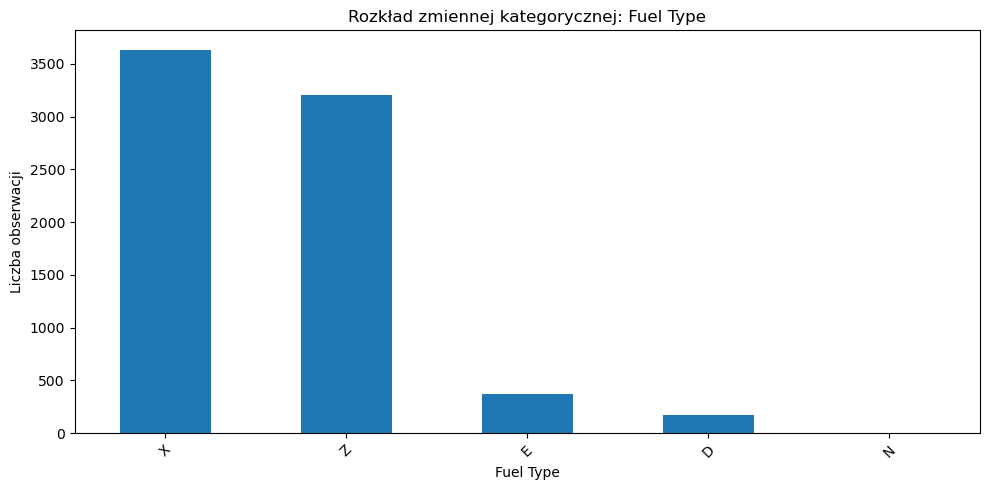

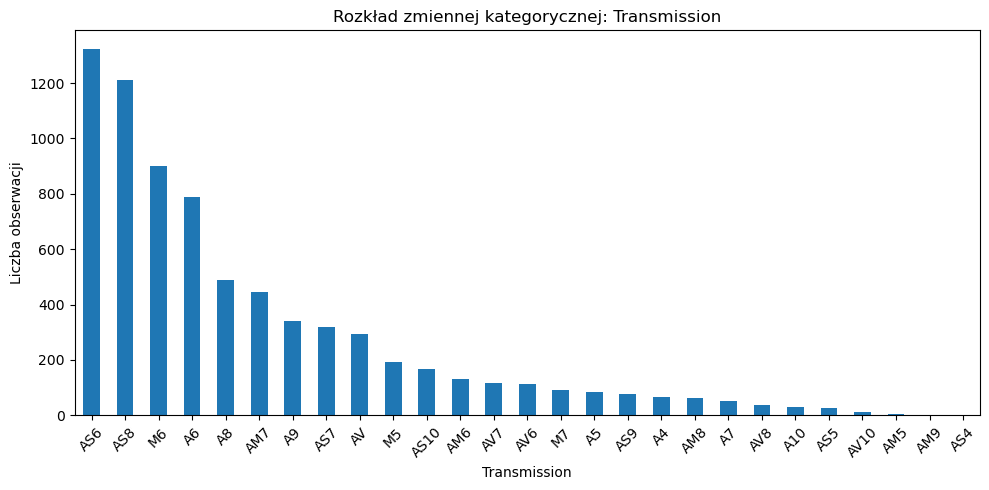

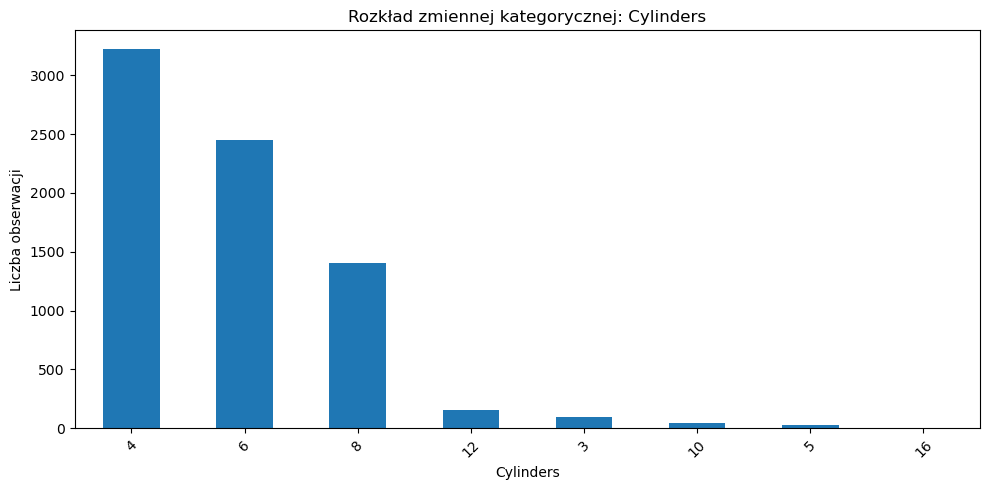

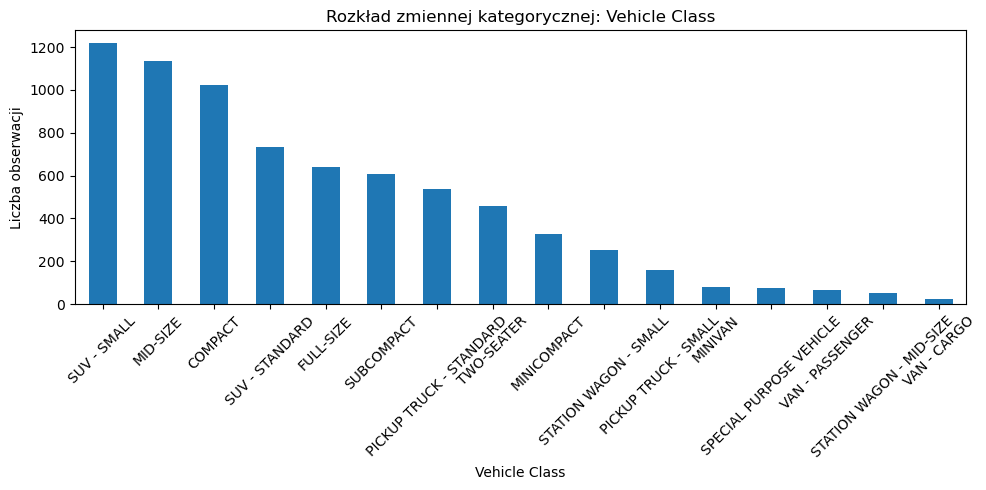

In [7]:
zmienne_kategoryczne = ['Fuel Type', 'Transmission', 'Cylinders', 'Vehicle Class']

for i in zmienne_kategoryczne:
    licz = df[i].value_counts()
    plt.figure(figsize=(10, 5))
    licz.plot(kind='bar')
    plt.title(f'Rozkład zmiennej kategorycznej: {i}')
    plt.xlabel(i)
    plt.ylabel('Liczba obserwacji')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

**Rodzaj paliwa:**  
Benzyna X (49%) i Z (43%) dominuje, a E85 (5%) i diesel (2,4%) są rzadkie. Wnioski dla tych dwóch grup mają mniejszą próbę.

**Skrzynia biegów:**  
Najczęstsze są AS6 (18%), AS8 (16%) i M6 (12%). Część z 27 kodów ma tylko kilka obserwacji, np. AS4 dwie, a AM9 trzy, dlatego rozdzielamy typ skrzyni i liczbę biegów.

**Klasa pojazdu:**  
Najwięcej jest SUV - SMALL (16,5%), MID-SIZE (15%) i COMPACT (14%). VAN - CARGO ma tylko 22 obserwacje.

**Liczba cylindrów:**  
Dominują silniki 4-, 6- i 8-cylindrowe (96% wierszy). Pozostałe wartości są rzadkie.

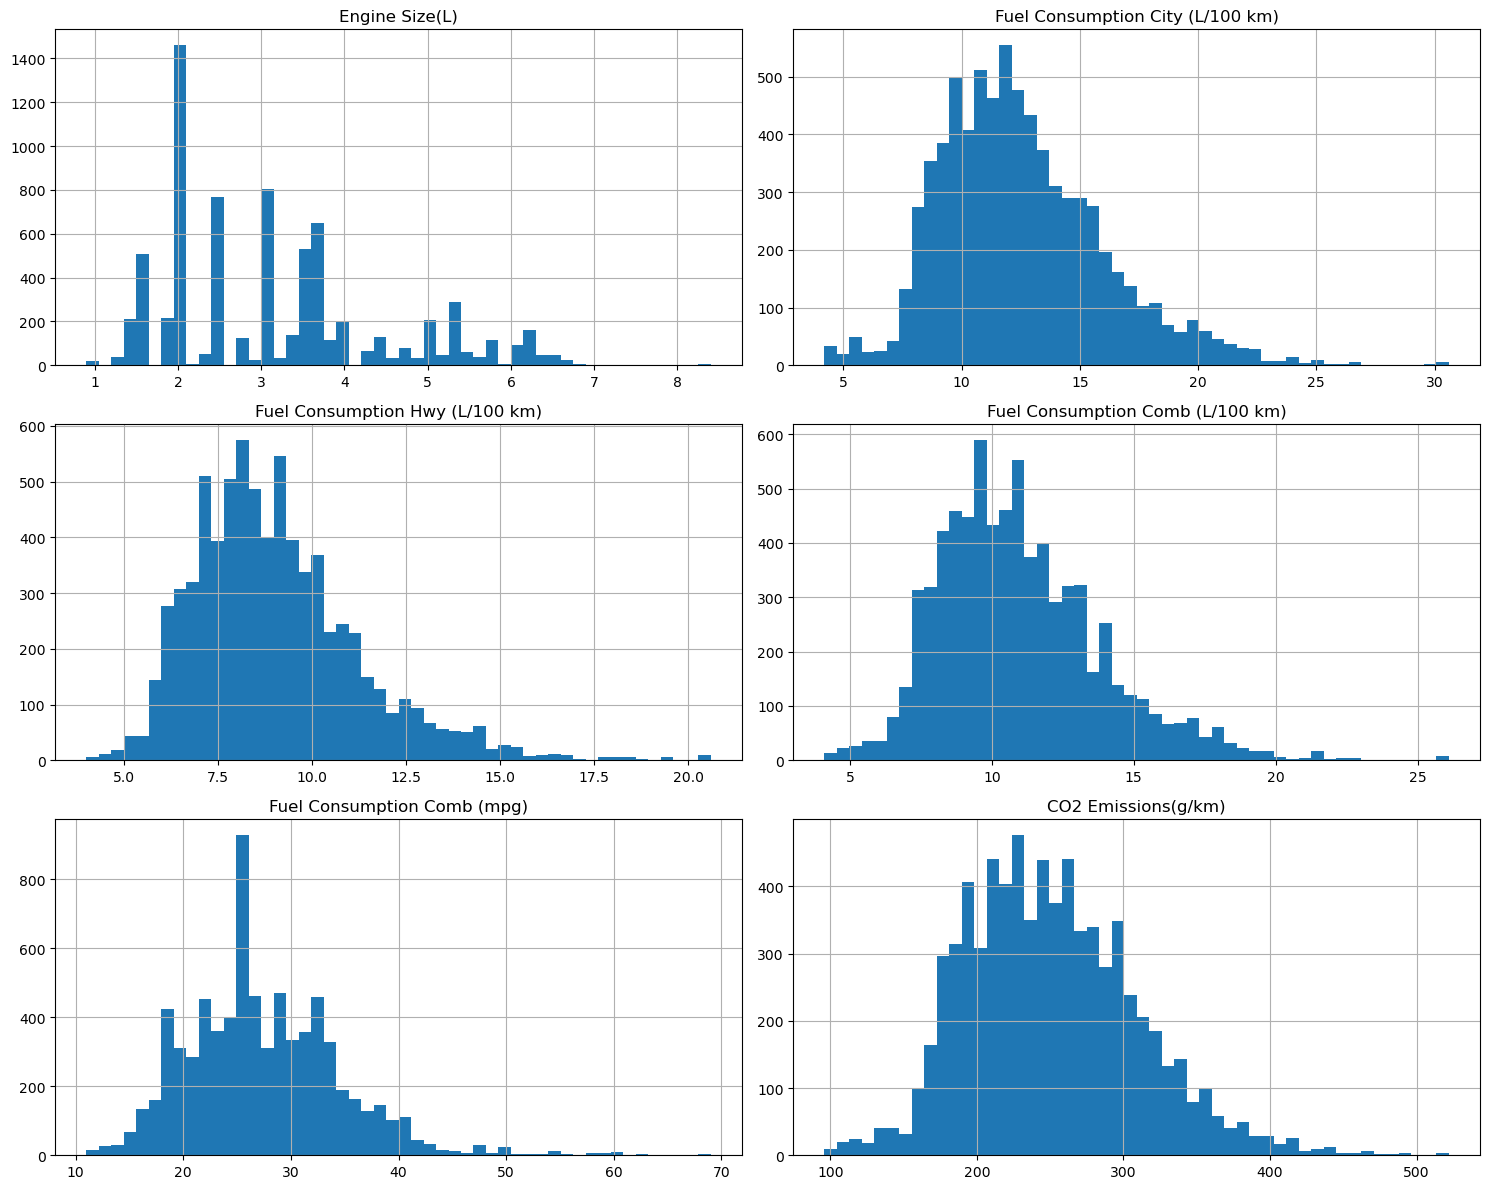

In [8]:
zmienne_numeryczne = ['Engine Size(L)', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)']

df[zmienne_numeryczne].hist(figsize=(15, 12), bins=50)
plt.tight_layout()
plt.show()

**Histogramy:**  
Rozkłady spalania, pojemności i CO₂ są prawoskośne, a większość aut leży w niższych wartościach.

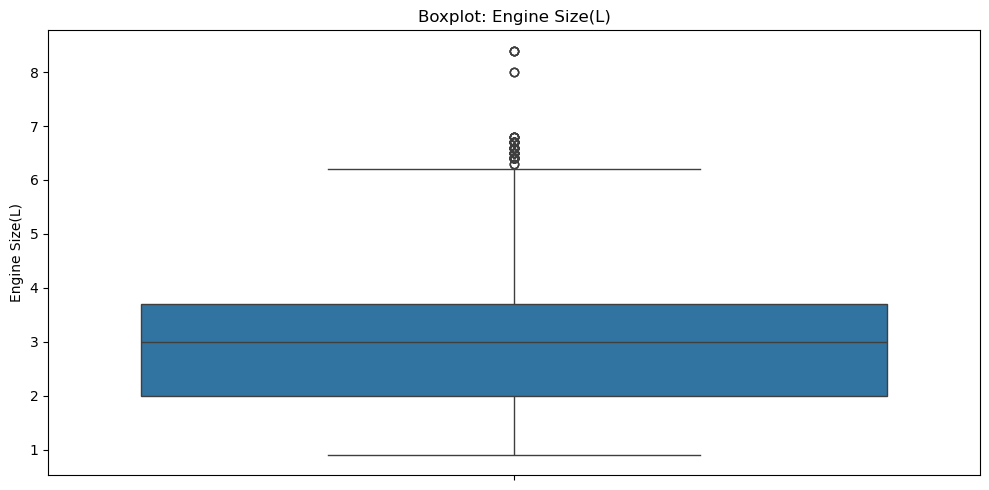

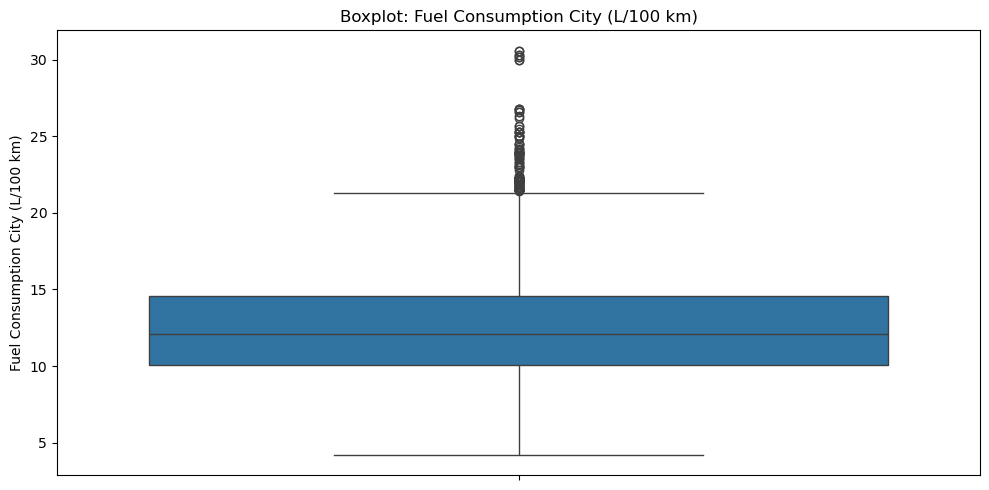

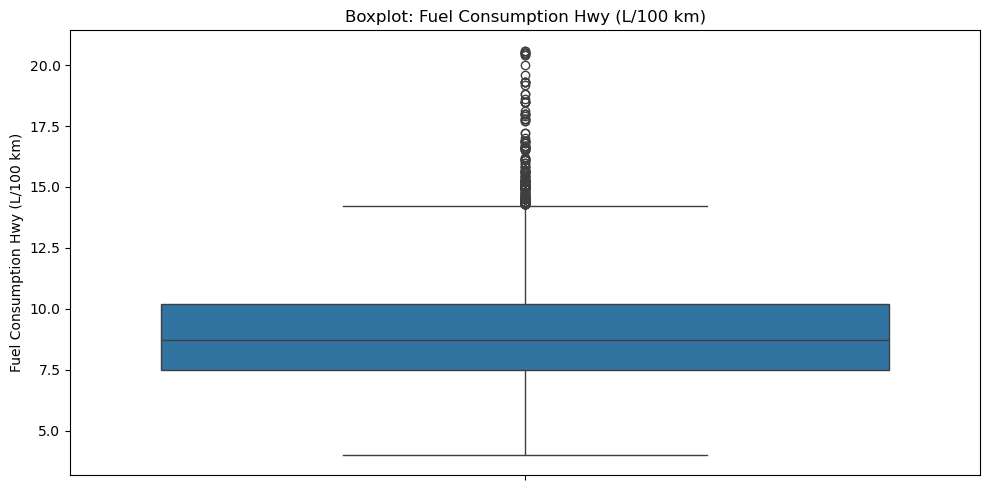

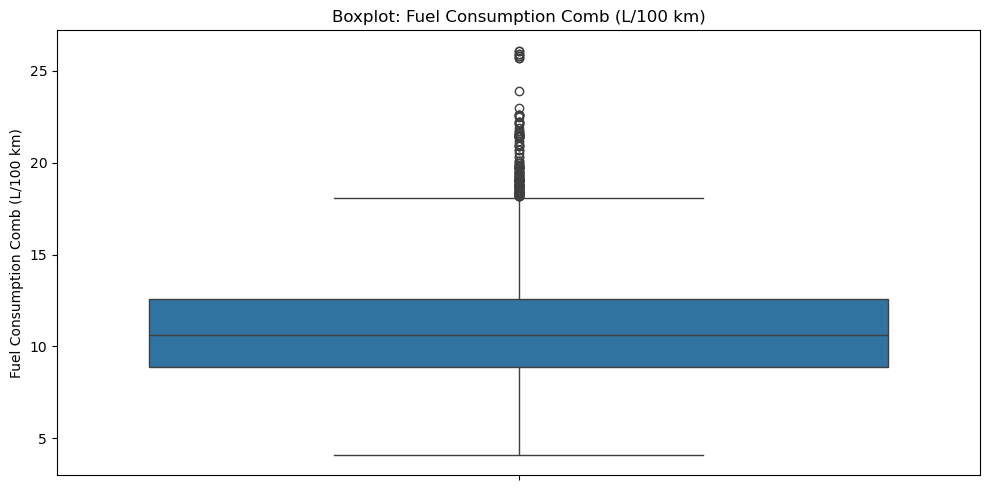

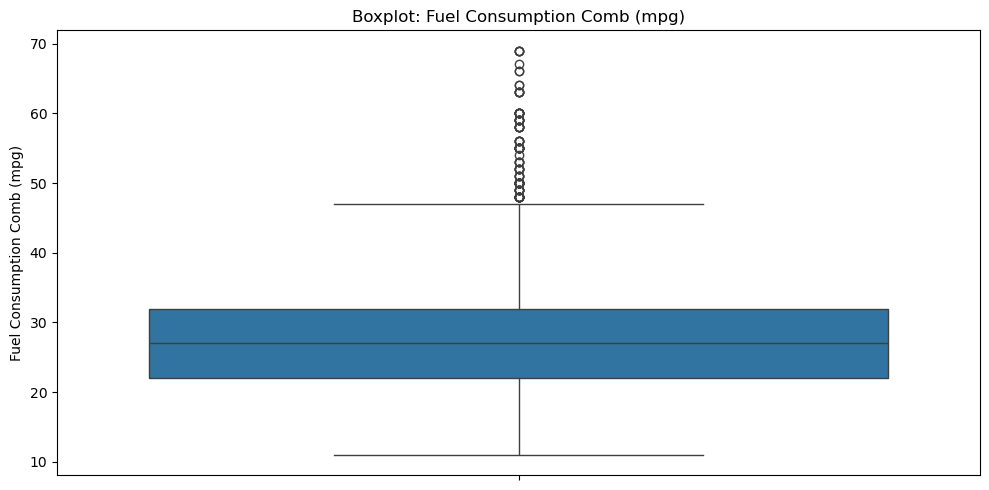

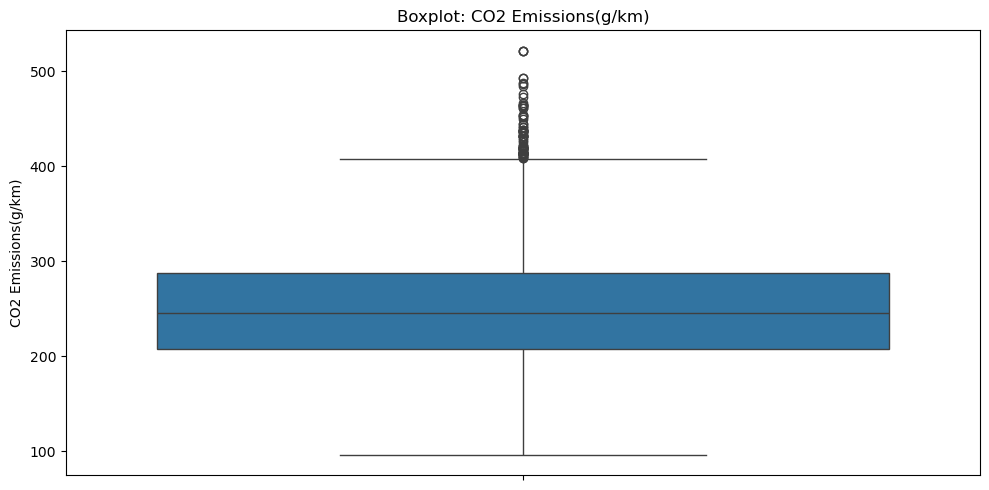

In [9]:
for i in zmienne_numeryczne:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, y=i)
    plt.title(f'Boxplot: {i}')
    plt.ylabel(i)
    plt.tight_layout()
    plt.show()

**Boxploty:**  
Poza wąsami leży od 80 obserwacji dla CO₂ do 208 dla spalania na trasie. Są to głównie realne, duże i paliwożerne auta.

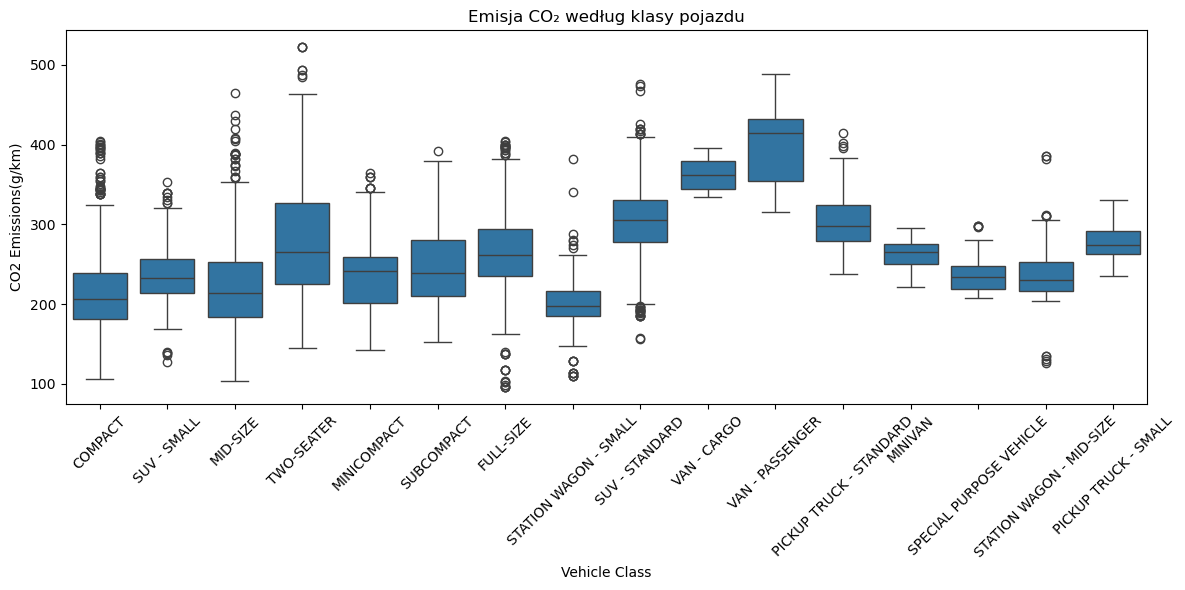

In [10]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Vehicle Class', y='CO2 Emissions(g/km)')
plt.xticks(rotation=45)
plt.title('Emisja CO₂ według klasy pojazdu')
plt.tight_layout()
plt.show()

**CO₂ a klasa pojazdu:**  
Mediana rośnie od ok. 200 g/km dla STATION WAGON - SMALL do ok. 420 g/km dla VAN - PASSENGER. Klasa silnie różnicuje emisję, co ma znaczenie przy wyborze aut do floty.

In [11]:
def find_outliers(group):
    Q1 = group['CO2 Emissions(g/km)'].quantile(0.25)
    Q3 = group['CO2 Emissions(g/km)'].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return group[(group['CO2 Emissions(g/km)'] < lower) | (group['CO2 Emissions(g/km)'] > upper)]

outliers = pd.concat(find_outliers(grupa) for _, grupa in df.groupby('Vehicle Class'))

In [12]:
outliers.sort_values('CO2 Emissions(g/km)', ascending=False)

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
5575,BUGATTI,Chiron,TWO-SEATER,8.0,16,AM7,Z,26.8,16.6,22.2,13,522
6640,BUGATTI,Chiron,TWO-SEATER,8.0,16,AM7,Z,26.8,16.6,22.2,13,522
4509,BUGATTI,CHIRON,TWO-SEATER,8.0,16,AM7,Z,26.8,16.6,22.2,13,522
7059,LAMBORGHINI,Aventador Roadster,TWO-SEATER,6.5,12,AM7,Z,26.6,15.8,21.7,13,493
6046,LAMBORGHINI,Aventador Roadster,TWO-SEATER,6.5,12,AM7,Z,26.6,15.8,21.7,13,493
...,...,...,...,...,...,...,...,...,...,...,...,...
6949,HYUNDAI,IONIQ,FULL-SIZE,1.6,4,AM6,X,4.2,4.2,4.2,67,99
4900,HYUNDAI,IONIQ BLUE,FULL-SIZE,1.6,4,AM6,X,4.2,4.0,4.1,69,96
5931,HYUNDAI,IONIQ Blue,FULL-SIZE,1.6,4,AM6,X,4.2,4.0,4.1,69,96
6950,HYUNDAI,IONIQ Blue,FULL-SIZE,1.6,4,AM6,X,4.2,4.0,4.1,69,96


Typy pojazdów z emisjami co2 mają wartości odstające, po sprawdzeniu w excelu wartości odstających to super samochody lub nisko emisyjne pojazdy.

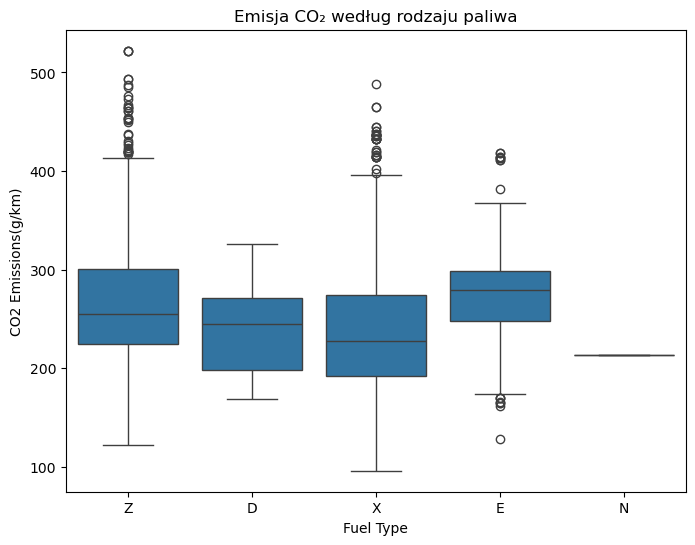

In [13]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Fuel Type', y='CO2 Emissions(g/km)')
plt.title('Emisja CO₂ według rodzaju paliwa')
plt.show()

E (czyli etanol e85) ma najwyższą medianę emisji, ponieważ używają jej auta z największymi silnikami.  
D (diesel) średnio emituje tyle co X (benzyna), chociaż pali mniej.

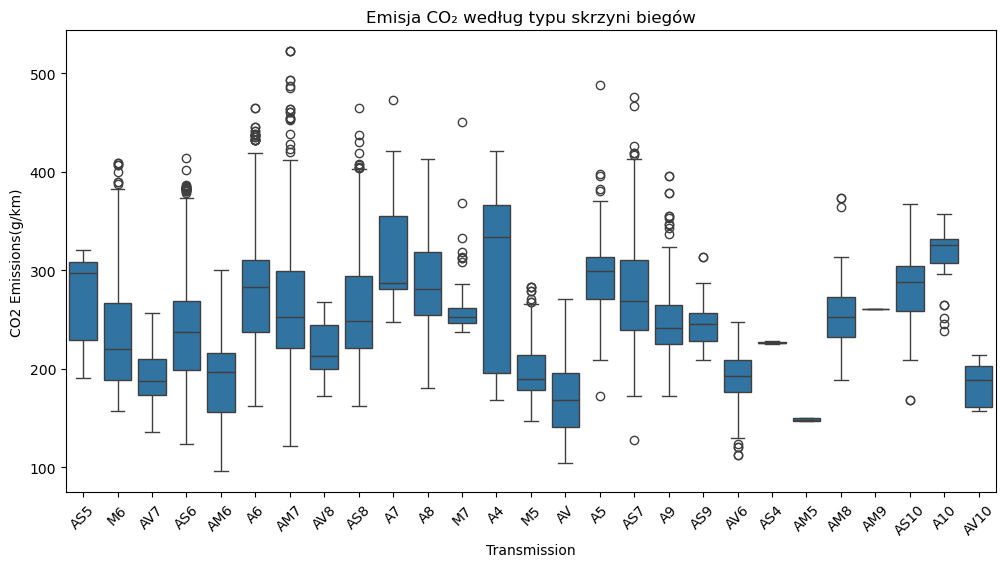

In [14]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Transmission', y='CO2 Emissions(g/km)')
plt.xticks(rotation=45)
plt.title('Emisja CO₂ według typu skrzyni biegów')
plt.show()

Skrzynia manualna z pozoru wygląda na oszczędną, ale to efekt mniejszych silników. W parach tych samych aut A i M są niemal równe, a AM, AS i AV palą o 0,2-0,4 L mniej od M.

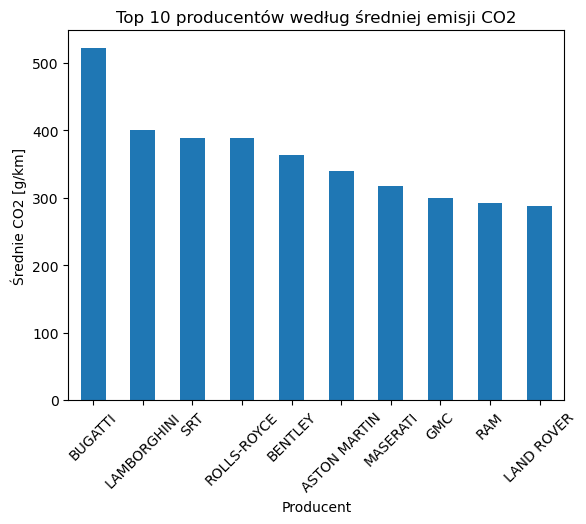

In [15]:
co2_by_make = (df.groupby('Make')['CO2 Emissions(g/km)'].mean().sort_values(ascending=False))
co2_by_make.head(10).plot(kind='bar')

plt.title('Top 10 producentów według średniej emisji CO2')
plt.ylabel('Średnie CO2 [g/km]')
plt.xlabel('Producent')
plt.xticks(rotation=45)
plt.show()

Bugatti ma 1 wiersz, a SRT 2, więc ich średnie nie są wiarygodne. GMC i RAM to marki masowe, wysoko przez dużą liczbę pickupów (45% i 93% konfiguracji).

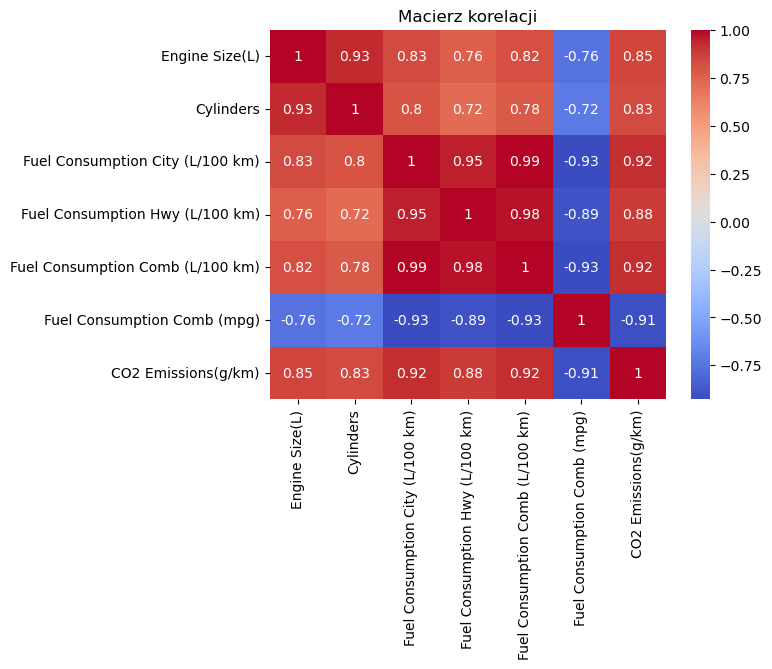

In [16]:
correlation = df.corr(numeric_only=True)
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Macierz korelacji')
plt.show()

CO₂ najsilniej wiąże się ze spalaniem w mieście i mieszanym (0,92), a słabiej z pojemnością (0,85) i cylindrami (0,83). Korelacja nie jest bliska 1, bo zależność biegnie osobno dla każdego paliwa.

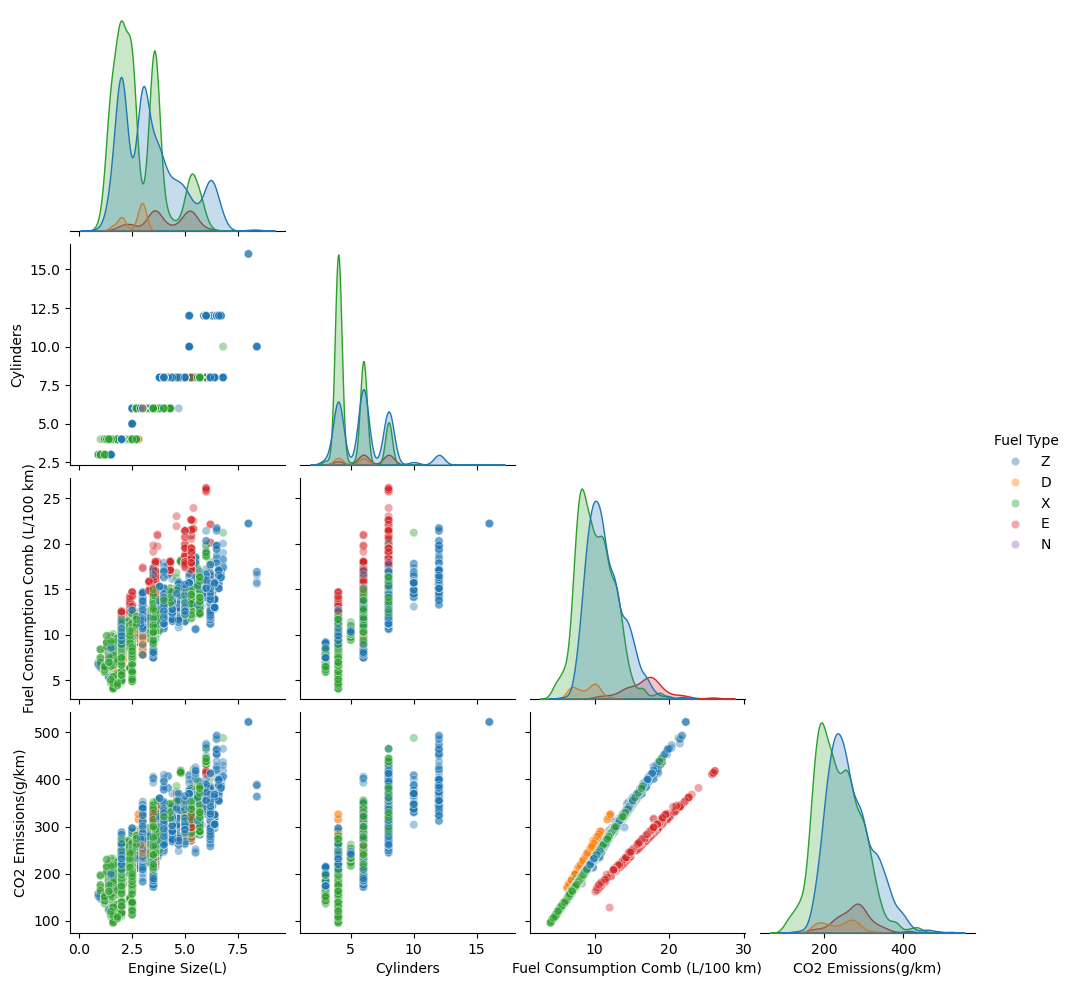

In [17]:
key = ["Engine Size(L)", "Cylinders", "Fuel Consumption Comb (L/100 km)", "CO2 Emissions(g/km)"]
key = [c for c in key if c in df.columns]
sns.pairplot(df[key + ["Fuel Type"]], hue="Fuel Type", corner=True, plot_kws={"alpha": 0.4})
plt.show()

Dla spalania i CO₂ punkty układają się w oddzielne proste dla kolejnych paliw. Potwierdza to, że spalanie i rodzaj paliwa niemal wyznaczają emisję.

## **Opis EDA**

Zbiór zawiera 7385 obserwacji i 12 zmiennych. Każdy wiersz opisuje jedną wersję modelu samochodu (marka, model, klasa, parametry silnika i skrzyni biegów) wraz z zużyciem paliwa oraz emisją CO2. Dane pochodzą z kanadyjskiego zestawienia Fuel Consumption Ratings (Natural Resources Canada) udostępnionego w serwisie Kaggle. Zmienną docelową analizy jest emisja CO2 [g/km].

**Czym są dane?**
|Kolumna | Typ i znaczenie |
|---------------|-------------|
|Make / Model Kategoryczne:| marka (42) i nazwa modelu (2053).|
|Vehicle Class Kategoryczna:| klasa pojazdu (16 klas).|
|Engine Size(L) Liczbowa:| pojemność silnika [L].|
|Cylinders Liczbowa dyskretna:| liczba cylindrów.|
|Transmission Kategoryczna:| kod skrzyni biegów (27 wartości).|
|Fuel Type Kategoryczna:| rodzaj paliwa (5 kodów).|
|Fuel Consumption City (L/100 km) Liczbowa:| spalanie w mieście [L/100 km].|
|Fuel Consumption Hwy (L/100 km) Liczbowa:| spalanie na trasie [L/100 km].|
|Fuel Consumption Comb (L/100 km) Liczbowa:| spalanie mieszane [L/100 km].|
|Fuel Consumption Comb (mpg) Liczbowa:| spalanie mieszane w jednostce mpg.|
|CO2 Emissions(g/km) Liczbowa:| emisja CO₂ [g/km], zmienna docelowa.|

**Co przewidujemy?**  
To zadanie regresji, przewidujemy CO2 Emissions (g/km).

#### **Kody kategorii**  
**Paliwa:**  
X - benzyna zwykła  
Z - benzyna premium  
D - diesel  
E - etanol E85  
N - gaz ziemny  
  
**Skrzynie:**  
A - automatyczna  
AM - zautomatyzowana manualna  
AS - automatyczna z trybem sekwencyjnym  
AV - bezstopniowa  
M - manualna  
  
**Granice danych**  
Zbiór nie zawiera roku obserwacji, przebiegu, stylu jazdy ani warunków drogowych. Nie opisuje pełnego cyklu życia pojazdu ani reprezentatywnej struktury polskiej floty. Liczności dotyczą konfiguracji katalogowych, a nie liczby aut na drogach.

*   **Braki danych:** brak, żadna kolumna nie zawiera pustych wartości.
*   **Duplikaty:** 1103 wierszy (14.9%) powtarza się w całości. Najpewniej to ten sam model raportowany w kolejnych rocznikach (zbiór nie ma kolumny z rokiem). Przed modelowaniem warto je usunąć zostaje wtedy 6282 unikalnych obserwacji. Średnia CO2 zmienia się po tym z 250.6 na 251.2 g/km, więc wnioski z analizy (liczonej na pełnym zbiorze) pozostają aktualne.
*   **Rzadkie kategorie:** paliwo N (gaz ziemny) występuje tylko raz, pojazdy 16-cylindrowe 3 razy, to za mało do wnioskowania.
*   **Wartości odstające:** metodą IQR (poza przedziałem [88; 408] g/km) wykryto 80 obserwacji (1.1%), wszystkie powyżej górnej granicy. To realne, bardzo paliwożerne auta (Bugatti Chiron - 522 g/km, Lamborghini, Rolls-Royce, duże vany), a nie błędy pomiaru, nie należy ich usuwać.
*   **Spójność:** wszystkie wartości są dodatnie i mieszczą się w realistycznych zakresach.

**Statystyki opisowe pełnego zbioru (N = 7385)**  
|Cecha| Średnia |Mediana |Min| Max|
|-|-|-|-|-|
|Silnik [L]| 3.16 |3.00| 0.90 |8.40|
|Cylindry |5.62 |6.00 |3.00 |16.00|
|Miasto [L/100 km] |12.56 |12.10 |4.20 |30.60|
|Trasa [L/100 km]| 9.04 |8.70 |4.00 |20.60|
|Mieszane [L/100 km] |10.98 |10.60 |4.10 |26.10|
|CO₂ [g/km]| 250.58| 246.00 |96.00 |522.00|  

Średnia emisja wynosi 250,58 g/km, a mediana 246 g/km. Środkowe 50% obserwacji mieści się w przedziale 208-288 g/km. Rozkład jest lekko prawoskośny (skośność ok. 0,53). Przeciętne spalanie mieszane wynosi 10,98 L/100 km.

W excelu w danych widzę, że zapis rekordów zmiennych tekstowych może różnić się uppercase'em i lowercase'm liter, należy to zweryfikować oraz poprawić.

## **Preprocessing**

Normalizacja sposobu zapisu cechy 'Model'.

In [18]:
df_norm = df.copy()
for kol in ["Make", "Model"]:
    df_norm[kol] = df_norm[kol].str.upper().str.strip()

dup_dokladne = df.duplicated().sum()
dup_po_norm = df_norm.duplicated().sum()

print("Duplikaty dokładne:", dup_dokladne)
print("Duplikaty po ujednoliceniu:", dup_po_norm)
print("Dodatkowe duplikaty:", dup_po_norm - dup_dokladne)
print("Modele przed:", df["Model"].nunique(), "| po:", df_norm["Model"].nunique())

warianty = df.groupby(df["Model"].str.upper())["Model"].unique()
print(warianty[warianty.map(len) > 1].head(5))

Duplikaty dokładne: 1103
Duplikaty po ujednoliceniu: 1395
Dodatkowe duplikaty: 292
Modele przed: 2053 | po: 1591
Model
124 SPIDER                            [124 SPIDER, 124 Spider]
1500 4X4 ECODIESEL    [1500 4X4 ECODIESEL, 1500 4X4 EcoDiesel]
1500 ECODIESEL                [1500 ECODIESEL, 1500 EcoDiesel]
230I CABRIOLET                [230i CABRIOLET, 230i Cabriolet]
230I COUPE                            [230i COUPE, 230i Coupe]
Name: Model, dtype: object


Po ujednoliceniu wielkości liter duplikatów jest 1395, a nie 1103. Liczba modeli spada z 2053 do 1591, więc ta sama nazwa bywała zapisana różnie, np. 124 SPIDER i 124 Spider.

Przeglądając dane w postaci tabelarycznej w Excelu, zauważyłem również, że dane są podzielone na 7 części posortowanych markami alfabetycznie. Zbiór nie ma kolumny z rokiem a duplikaty które mogły się znaleźć w dataframe mogą wynikać z występowania między blokami danych, może to być spowodowane różnicą np w wieku auta. Dobrym pomysłem może okazać się umieszczenie informacji, w której części danych znalazł się dany rekord o aucie.

In [19]:
marka = df_norm["Make"].str.upper()
df_norm["blok"] = (marka < marka.shift()).cumsum()
cechy_bez_bloku = df_norm.columns.drop("blok")

In [20]:
df_unikalne = df_norm.drop_duplicates(subset=cechy_bez_bloku)

rzadkie = df_unikalne.groupby("Cylinders").agg(
    wiersze_unikalne=("Model", "size"),
    modele=("Model", "nunique"),
    marki=("Make", "nunique"),
)
rzadkie.insert(0, "wiersze_pelny_zbior", df_norm["Cylinders"].value_counts())
print(rzadkie)

kol = ["Make", "Model", "Fuel Consumption Comb (L/100 km)", "CO2 Emissions(g/km)"]
print(df_norm.loc[df_norm["Cylinders"] == 16, kol])

           wiersze_pelny_zbior  wiersze_unikalne  modele  marki
Cylinders                                                      
3                           95                80      19      5
4                         3220              2611     666     34
5                           26                26      17      3
6                         2446              1931     635     32
8                         1402              1170     371     26
10                          42                40      19      5
12                         151               131      53      7
16                           3                 1       1      1
         Make   Model  Fuel Consumption Comb (L/100 km)  CO2 Emissions(g/km)
4509  BUGATTI  CHIRON                              22.2                  522
5575  BUGATTI  CHIRON                              22.2                  522
6640  BUGATTI  CHIRON                              22.2                  522


Trzy wiersze z 16 cylindrami to jeden Bugatti Chiron z identycznymi parametrami, więc nie da się z nich wnioskować o tej grupie. Silniki 5-cylindrowe też są rzadkie, bo mają 26 wierszy, 17 modeli i tylko 3 marki.

In [21]:
df_model = df_norm.drop_duplicates(subset=cechy_bez_bloku)
#paliwo N występuje 1 raz, usuwam, ponieważ zaburza dane dla modelu
df_model = df_model[df_model["Fuel Type"] != "N"].copy()

## **Inżynieria cech**

In [22]:
#typ skrzyni
df_model["Trans_type"] = df_model["Transmission"].str.extract(r"^([A-Z]+)")[0]
df_model["Gears"] = pd.to_numeric(df_model["Transmission"].str.extract(r"(\d+)")[0], errors="coerce")

braki = df_model["Gears"].isna()
print("Braki Gears:", braki.sum())
print(df_model.loc[braki, "Transmission"].value_counts())

#usuwanie zbędnej kolumny po podziale
df_model = df_model.drop(columns=['Transmission'])

#braki jako 0 (bo braki są tylko w AV, czyli w skrzyniach bezstopniowych - biegów nie brakuje, bo ich nie mają) a zmienną zmieniamy w kategoryczną
df_model["Gears_kat"] = df_model["Gears"].fillna(0).astype("Int64").astype("string")
df_model["Cylinders_kat"] = df_model["Cylinders"].astype("string")

#usuwanie zbędnych kolumn po zmianie na kategoryczne
df_model = df_model.drop(columns=['Gears', 'Cylinders'])

#flagi z nazwy modelu
nazwa = df_model["Model"]
df_model["Hybrid_nazwa"] = nazwa.str.contains("HYBRID", regex=False).astype(int)
df_model["FFV"] = nazwa.str.contains("FFV", regex=False).astype(int)
df_model["Naped_4x4"] = nazwa.str.contains(r"4WD|AWD|4X4|4MATIC|QUATTRO|XDRIVE").astype(int)

#przeglad nowych cech
print(df_model[["Hybrid_nazwa", "FFV", "Naped_4x4"]].sum())

Braki Gears: 224
Transmission
AV    224
Name: count, dtype: int64
Hybrid_nazwa     110
FFV              492
Naped_4x4       2135
dtype: int64


**Trans_type (typ skrzyni):**  
Cecha rozdziela informację zapisaną w kodzie `Transmission`. Skrzynie o różnej konstrukcji mogą inaczej przenosić moc silnika na koła, co może wpływać na emisję. Zamiast 27 kodów model dostaje 5 czytelnych typów, więc łatwiej znajdzie wspólne wzorce, także przy rzadkich kodach.

**Gears (liczba biegów):**  
Większa liczba biegów może pozwalać silnikowi częściej pracować w korzystnym zakresie obrotów, co może obniżać emisję. Cecha jest kategoryczna, ponieważ ma niewiele wartości, a jej związek z CO₂ nie musi być liniowy. Skrzynie bezstopniowe bez liczby w kodzie dostają kategorię `0`, ponieważ nie mają klasycznych biegów, a ich uzupełnianie tworzyłoby fałszywą informację.

**Cylinders (liczba cylindrów):**  
Liczba cylindrów opisuje konstrukcję i wielkość silnika, a więc pośrednio jego zapotrzebowanie na paliwo. Traktujemy ją jako kategorię, ponieważ przyjmuje kilka typowych wartości, a przejścia między nimi nie muszą zmieniać emisji o stałą wartość.

**Hybrid_nazwa (hybryda w nazwie):**  
Napęd hybrydowy może odzyskiwać energię i odciążać silnik spalinowy, więc emisja może być niższa, niż sugerowałaby sama pojemność. Bez tej flagi informacja ta zniknęłaby po usunięciu kolumny `Model`. Flaga nie wykrywa wszystkich hybryd, ponieważ część z nich nie ma tego słowa w nazwie.

**FFV (pojazd wielopaliwowy):**  
Oznacza auta przystosowane do pracy na różnych paliwach, np. na benzynie i E85. Jest to odrębna grupa konstrukcji, a dodatkowo wyróżnia informację niedostępną w pozostałych kolumnach. Może to pomóc modelowi lepiej odróżnić takie pojazdy od pozostałych.

**Naped_4x4 (napęd na wiele osi):**  
Napęd na więcej kół zwykle zwiększa masę i opory układu, co może podnosić zużycie paliwa, a więc i emisję CO₂. Informacja jest zapisana tylko w nazwie modelu, dlatego wyciągamy ją przed jej usunięciem.

In [23]:
cechy_kategoryczne = ["Make", "Vehicle Class", "Fuel Type", "Trans_type", "Gears_kat", "Cylinders_kat"]
cechy_binarne = ["Hybrid_nazwa", "FFV", "Naped_4x4"]
cechy_numeryczne = ["Engine Size(L)"]
cel = "CO2 Emissions(g/km)"

cechy_spalania = [
    "Fuel Consumption City (L/100 km)",
    "Fuel Consumption Hwy (L/100 km)",
    "Fuel Consumption Comb (L/100 km)",
    "Fuel Consumption Comb (mpg)",
]
df_final = df_model.drop(columns=cechy_spalania + ["blok"])
df_final = df_final.drop_duplicates()

X = df_final[cechy_numeryczne + cechy_kategoryczne + cechy_binarne]
y = df_final[cel]

print("X:", X.shape, "| y:", y.shape)
print("Spalanie w X:", any("Consumption" in kol for kol in X.columns))
print("Braki w X:", X.isna().sum().sum())

X: (5637, 10) | y: (5637,)
Spalanie w X: False
Braki w X: 0


**Usunięcie cech spalania:**  
Z modelu usuwamy spalanie w mieście, na trasie, mieszane oraz w mpg. W analizie EDA emisja CO₂ okazała się niemal bezpośrednio wynikać ze wzoru `spalanie mieszane × współczynnik paliwa`. Pozostawienie tych cech sprowadziłoby zadanie do odtworzenia prostej zależności fizycznej, którą można policzyć bez uczenia maszynowego. Po ich usunięciu model przewiduje emisję wyłącznie na podstawie parametrów technicznych pojazdu: marki, klasy, paliwa, silnika i skrzyni. Odpowiada to sytuacji, w której firma chce wstępnie oszacować emisję auta, gdy nie zna jego spalania. Dzięki temu model ma rzeczywiste zadanie do wykonania, a porównanie algorytmów ma sens praktyczny. Kosztem tej decyzji jest mniejsza dokładność, ponieważ model traci najsilniejszy predyktor emisji. Usuwamy również cechę `blok`, ponieważ nie jest ona kolumną danych, lecz przybliżeniem wywnioskowanym z kolejności wierszy, a dla nowego auta nie miałaby wartości.

## **Pipeline**  
Przygotowuję pipeline, który skaluje cechę liczbową i koduje cechy kategoryczne, a flagi binarne przekazuje bez zmian.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#pipeline dla cech liczbowych
pipeline_num = Pipeline([
    ("skalowanie", StandardScaler()),
])

#pipeline dla cech kategorycznych
pipeline_kat = Pipeline([
    ("kodowanie", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

#połączenie
preprocessor = ColumnTransformer([
    ("num", pipeline_num, cechy_numeryczne),
    ("kat", pipeline_kat, cechy_kategoryczne),
    ("bin", "passthrough", cechy_binarne),
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Train:", X_train_prep.shape, "| Test:", X_test_prep.shape)

Train: (4509, 85) | Test: (1128, 85)


**Podział danych:**  
Zastosowaliśmy losowy podział 80/20 za pomocą `train_test_split`. Ten sam model auta może więc występować w zbiorze treningowym i testowym w różnych wersjach. Wynik opisuje skuteczność dla aut podobnych do tych z katalogu i może być optymistyczny dla modeli całkowicie nowych.

## **Jak wyglądają dane po wszystkich operacjach tuż przed trenowaniem modeli?**

In [25]:
#rozmiary zbiorów
podsumowanie = pd.DataFrame({
    "wiersze": [len(X_train), len(X_test)],
    "udział": [len(X_train) / len(X), len(X_test) / len(X)],
    "kolumny przed pipeline": [X_train.shape[1], X_test.shape[1]],
    "kolumny po pipeline": [X_train_prep.shape[1], X_test_prep.shape[1]],
    "braki po pipeline": [pd.isna(X_train_prep).sum(), pd.isna(X_test_prep).sum()],
}, index=["train", "test"])
display(podsumowanie.round(3))

,wiersze,udział,kolumny przed pipeline,kolumny po pipeline,braki po pipeline
train,4509,0.8,10,85,0
test,1128,0.2,10,85,0


In [26]:
#porównanie zmiennej docelowej i pojemności silnika
porownanie = pd.DataFrame({
    "CO₂ train": y_train.describe(),
    "CO₂ test": y_test.describe(),
    "Pojemność train": X_train["Engine Size(L)"].describe(),
    "Pojemność test": X_test["Engine Size(L)"].describe(),
})
display(porownanie.round(2))

,CO₂ train,CO₂ test,Pojemność train,Pojemność test
count,4509.00,1128.00,4509.00,1128.00
mean,251.78,250.95,3.18,3.15
std,59.42,59.06,1.37,1.38
min,96.00,110.00,0.90,1.00
25%,207.00,209.00,2.00,2.00
50%,246.00,246.00,3.00,3.00
75%,290.00,283.25,3.80,3.80
max,493.00,522.00,8.40,8.40


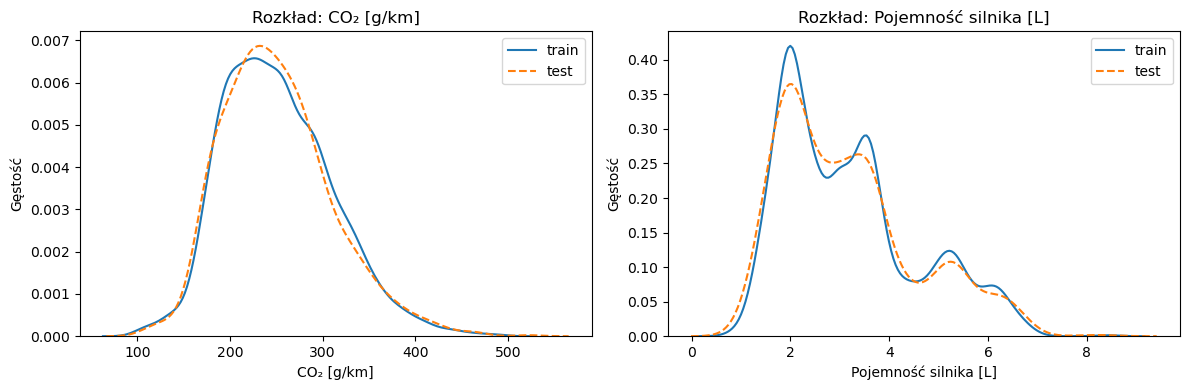

In [27]:
#rozkład CO₂ i pojemności w obu zbiorach
fig, osie = plt.subplots(1, 2, figsize=(12, 4))
for os_wykresu, tr, te, tytul in [
    (osie[0], y_train, y_test, "CO₂ [g/km]"),
    (osie[1], X_train["Engine Size(L)"], X_test["Engine Size(L)"], "Pojemność silnika [L]"),
]:
    sns.kdeplot(tr, ax=os_wykresu, label="train")
    sns.kdeplot(te, ax=os_wykresu, label="test", linestyle="--")
    os_wykresu.set_title(f"Rozkład: {tytul}")
    os_wykresu.set_xlabel(tytul)
    os_wykresu.set_ylabel("Gęstość")
    os_wykresu.legend()
plt.tight_layout()
plt.show()

In [28]:
#udziały kategorii i flag w train i test
wiersze = []
for cecha in cechy_kategoryczne + cechy_binarne:
    udzial_train = X_train[cecha].value_counts(normalize=True)
    udzial_test = X_test[cecha].value_counts(normalize=True)
    roznica = udzial_train.subtract(udzial_test, fill_value=0).abs().max()
    wiersze.append({
        "cecha": cecha,
        "kategorie train": X_train[cecha].nunique(),
        "kategorie test": X_test[cecha].nunique(),
        "tylko w test": len(set(X_test[cecha]) - set(X_train[cecha])),
        "największy rozjazd [p.p.]": round(100 * roznica, 2),
    })
display(pd.DataFrame(wiersze).set_index("cecha"))

,kategorie train,kategorie test,tylko w test,największy rozjazd [p.p.]
cecha,,,,
Make,41,41,1,0.84
Vehicle Class,16,16,0,2.29
Fuel Type,4,4,0,2.38
Trans_type,5,5,0,1.82
Gears_kat,8,8,0,1.13
Cylinders_kat,7,8,1,0.84
Hybrid_nazwa,2,2,0,0.64
FFV,2,2,0,0.87
Naped_4x4,2,2,0,1.99


In [29]:
#dane po przekształceniu
nazwy = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_prep, columns=nazwy, index=X_train.index)
X_test_df = pd.DataFrame(X_test_prep, columns=nazwy, index=X_test.index)
display(X_train_df.head())

,num__Engine Size(L),kat__Make_ACURA,kat__Make_ALFA ROMEO,kat__Make_ASTON MARTIN,kat__Make_AUDI,kat__Make_BENTLEY,kat__Make_BMW,kat__Make_BUICK,kat__Make_CADILLAC,kat__Make_CHEVROLET,...,kat__Cylinders_kat_10,kat__Cylinders_kat_12,kat__Cylinders_kat_3,kat__Cylinders_kat_4,kat__Cylinders_kat_5,kat__Cylinders_kat_6,kat__Cylinders_kat_8,bin__Hybrid_nazwa,bin__FFV,bin__Naped_4x4
7124,-0.133627,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
322,-1.303290,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4691,-1.595706,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1975,-1.010874,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5920,-1.157082,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [30]:
#min max srednia
skalowanie = pd.DataFrame({
    "train": X_train_df["num__Engine Size(L)"].agg(["mean", "std", "min", "max"]),
    "test": X_test_df["num__Engine Size(L)"].agg(["mean", "std", "min", "max"]),
})
display(skalowanie.round(3))

,train,test
mean,-0.000,-0.022
std,1.000,1.007
min,-1.669,-1.596
max,3.814,3.814


In [31]:
#liczba kolumn po pipeline
grupy_kolumn = pd.Series(nazwy).str.split("__").str[0].value_counts()
print("Liczba kolumn po pipeline:")
print(grupy_kolumn.rename({"num": "liczbowe", "kat": "one-hot", "bin": "binarne"}))

Liczba kolumn po pipeline:
one-hot     81
binarne      3
liczbowe     1
Name: count, dtype: int64


## **Modele i miara oceny jakości modeli**

**Miary porównania modeli:**  
Główną miarą jest MAE, ponieważ podaje średni błąd w g/km, jest łatwa do interpretacji biznesowej i mniej wrażliwa na pozostawione w zbiorze auta odstające niż RMSE. Drugim kryterium jest czas uczenia modelu, który pokazuje praktyczny koszt jego użycia. RMSE i R² są miarami pomocniczymi: RMSE pozwala ocenić wpływ dużych błędów, a R² pokazuje, jaką część zmienności emisji wyjaśnia model. Modele oceniamy 5-krotną walidacją krzyżową na zbiorze treningowym, a zbiór testowy pozostaje nietknięty do końcowej oceny.

**Wybór modeli:**  
Do porównania wybraliśmy trzy modele, z których każdy reprezentuje inne podejście do danych. Pozwala to ocenić, ile zyskujemy wraz ze wzrostem złożoności modelu.

**Ridge (baseline):**  
To prosty model liniowy z regularyzacją. Pełni rolę punktu odniesienia i pokazuje, ile emisji CO₂ da się wyjaśnić zależnościami liniowymi. Wybraliśmy go zamiast zwykłej regresji liniowej, ponieważ kodowanie one-hot tworzy wiele kolumn zależnych od siebie, a regularyzacja stabilizuje wyniki. Model jest też bardzo szybki i łatwy do zinterpretowania.

**HistGradientBoostingRegressor (boosting):**  
To model, w którym kolejne drzewa uczą się na błędach poprzednich. Dobrze radzi sobie z danymi tabelarycznymi, wychwytuje zależności nieliniowe oraz interakcje między cechami, np. między klasą pojazdu a pojemnością silnika. Uczy się szybko i zwykle dużo zyskuje na strojeniu hiperparametrów.

**RandomForestRegressor (las losowy):**  
To model uśredniający wyniki wielu niezależnych drzew. Podobnie jak boosting wychwytuje nieliniowości i interakcje, ale uczy drzewa równolegle, a nie kolejno. Uśrednianie zmniejsza wrażliwość na pojedyncze obserwacje, co ma znaczenie, ponieważ pozostawiliśmy w zbiorze auta odstające. Dzięki temu możemy też porównać dwie różne strategie budowy zespołu drzew.

Modele oceniamy tymi samymi miarami i na tych samych foldach walidacji krzyżowej, dzięki czemu wyniki są porównywalne.

## **Trenowanie**

In [32]:
modele = {
    "Ridge (baseline)": Ridge(),
    "Boosting": HistGradientBoostingRegressor(random_state=42),
    "Las losowy": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
metryki = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

wyniki = []
wytrenowane = {}

for nazwa, model in modele.items():
    pipeline = Pipeline([("preprocessing", preprocessor), ("model", model)])
    cv_wyniki = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=metryki, return_train_score=True)

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    czas_uczenia = time.perf_counter() - start
    wytrenowane[nazwa] = pipeline

    wyniki.append({
        "model": nazwa,
        "MAE walidacja [g/km]": -cv_wyniki["test_MAE"].mean(),
        "MAE odch. std": cv_wyniki["test_MAE"].std(),
        "MAE trening [g/km]": -cv_wyniki["train_MAE"].mean(),
        "RMSE walidacja [g/km]": -cv_wyniki["test_RMSE"].mean(),
        "R2 walidacja": cv_wyniki["test_R2"].mean(),
        "Czas uczenia [s]": czas_uczenia,
    })

tabela_wynikow = pd.DataFrame(wyniki).set_index("model").sort_values("MAE walidacja [g/km]")
display(tabela_wynikow.round(3))

,MAE walidacja [g/km],MAE odch. std,MAE trening [g/km],RMSE walidacja [g/km],R2 walidacja,Czas uczenia [s]
model,,,,,,
Las losowy,9.061,0.191,5.921,13.350,0.949,0.628
Boosting,10.814,0.329,9.407,14.892,0.937,0.378
Ridge (baseline),14.558,0.500,14.245,19.644,0.891,0.027


Najlepszy wynik osiągnął las losowy: MAE w walidacji wyniosło 9,06 g/km, RMSE 13,35 g/km, a R² 0,949. Boosting uzyskał MAE 10,81 g/km i R² 0,937. Ridge, czyli baseline, uzyskał MAE 14,56 g/km i R² 0,891. Oba modele drzewiaste wyraźnie pokonały baseline, co oznacza, że w danych występują zależności nieliniowe i interakcje między cechami.

Przewaga lasu losowego nad boostingiem wynosi około 1,75 g/km i jest większa niż rozrzut wyników między foldami (0,19 i 0,33 g/km), ale oba modele działają na domyślnych hiperparametrach, więc ta kolejność może się zmienić po strojeniu.

Największą różnicę między błędem treningowym a walidacyjnym ma las losowy (5,92 i 9,06 g/km), co wskazuje na częściowe dopasowanie do danych treningowych. Boosting ma mniejszą różnicę (9,41 i 10,81 g/km), a Ridge prawie żadnej (14,25 i 14,56 g/km), co oznacza, że jego ograniczeniem jest prostota modelu.

Wszystkie modele uczą się bardzo szybko: Ridge 0,02 s, boosting 0,39 s, a las losowy 0,60 s. Czas uczenia nie jest więc w tym zbiorze przeszkodą i nie zmienia kolejności wyznaczonej przez MAE. Wyniki dotyczą aut podobnych do tych z katalogu, ponieważ podział jest losowy.

## **Optymalizacja hiperparametrów**

In [33]:
wyniki_strojenia = {}
najlepsze_modele = {}
najlepsze_parametry = {}

def strój_model(nazwa, siatka, liczba_prob):
    szukanie = RandomizedSearchCV(
        wytrenowane[nazwa],
        param_distributions=siatka,
        n_iter=liczba_prob,
        scoring=metryki,
        refit="MAE",
        cv=cv,
        random_state=42,
        return_train_score=True,
    )
    start = time.perf_counter()
    szukanie.fit(X_train, y_train)
    czas_szukania = time.perf_counter() - start

    najlepsze_modele[nazwa] = szukanie.best_estimator_
    najlepsze_parametry[nazwa] = szukanie.best_params_
    nr = szukanie.best_index_
    wyniki_cv = szukanie.cv_results_

    wyniki_strojenia[nazwa] = {
        "MAE walidacja [g/km]": -wyniki_cv["mean_test_MAE"][nr],
        "MAE odch. std": wyniki_cv["std_test_MAE"][nr],
        "MAE trening [g/km]": -wyniki_cv["mean_train_MAE"][nr],
        "RMSE walidacja [g/km]": -wyniki_cv["mean_test_RMSE"][nr],
        "R2 walidacja": wyniki_cv["mean_test_R2"][nr],
        "Czas uczenia [s]": szukanie.refit_time_,
        "Czas strojenia [s]": czas_szukania,
    }

    print(nazwa, szukanie.best_params_)
    print(f"MAE walidacja: {wyniki_strojenia[nazwa]['MAE walidacja [g/km]']:.3f} | czas strojenia: {czas_szukania:.1f} s")

**Ridge**

In [34]:
siatka_ridge = {"model__alpha": [0.01, 0.1, 0.5, 1, 2, 5, 10, 50, 100],}
strój_model("Ridge (baseline)", siatka_ridge, liczba_prob=9)

Ridge (baseline) {'model__alpha': 0.01}
MAE walidacja: 14.543 | czas strojenia: 1.9 s


**Boosting**

In [35]:
siatka_boosting = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "model__max_iter": [200, 400, 800],
    "model__max_leaf_nodes": [15, 31, 63, 127],
    "model__min_samples_leaf": [2, 5, 10, 20],
    "model__l2_regularization": [0, 0.1, 1, 10],
}
strój_model("Boosting", siatka_boosting, liczba_prob=20)

Boosting {'model__min_samples_leaf': 2, 'model__max_leaf_nodes': 31, 'model__max_iter': 800, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.1}
MAE walidacja: 8.670 | czas strojenia: 281.8 s


**Random Forest**

In [36]:
siatka_las = {
    "model__n_estimators": [300, 500],
    "model__max_depth": [None, 25],
    "model__min_samples_leaf": [1],
    "model__max_features": [0.33, 0.5, 1.0],
}
strój_model("Las losowy", siatka_las, liczba_prob=12)

Las losowy {'model__n_estimators': 500, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}
MAE walidacja: 8.967 | czas strojenia: 52.5 s


In [37]:
tabela_strojenia = (
    pd.DataFrame(wyniki_strojenia).T
    .rename_axis("model")
    .sort_values("MAE walidacja [g/km]")
)
display(tabela_strojenia.round(3))

,MAE walidacja [g/km],MAE odch. std,MAE trening [g/km],RMSE walidacja [g/km],R2 walidacja,Czas uczenia [s],Czas strojenia [s]
model,,,,,,,
Boosting,8.670,0.248,5.489,12.834,0.953,2.524,281.771
Las losowy,8.967,0.223,5.897,13.163,0.951,0.764,52.451
Ridge (baseline),14.543,0.521,14.221,19.644,0.891,0.019,1.933


**Wnioski z optymalizacji hiperparametrów:**  
Najlepszy wynik w walidacji osiągnął boosting po strojeniu: MAE spadło z 10,81 do 8,67 g/km, a R² wzrosło z 0,937 do 0,953. Najlepsze hiperparametry to `learning_rate=0.1`, `max_iter=800`, `max_leaf_nodes=31`, `min_samples_leaf=2` i `l2_regularization=0.1`. Większa liczba iteracji pozwoliła modelowi dokładniej uczyć się kolejnych błędów, a małe liście i słaba regularyzacja zachowały jego elastyczność. Wartość `max_iter=800` leży na górnej granicy sprawdzanego zakresu, więc dalsze zwiększanie mogłoby jeszcze nieco zmienić wynik. Czas uczenia wzrósł z około 0,3 do około 2,4 s, a całe strojenie zajęło około 265 s.

Las losowy po poprawie siatki uzyskał MAE 8,97 g/km, czyli poprawę o 0,09 g/km względem modelu domyślnego (9,06 g/km). Najlepsze hiperparametry to `n_estimators=500`, `max_depth=None`, `min_samples_leaf=1` i `max_features=0.5`. Pierwsze strojenie pogorszyło wynik (MAE 9,54 g/km), ponieważ najlepsza wylosowana kombinacja miała `min_samples_leaf=2`, a próg ten osłabia dopasowanie lasu w tym zbiorze. Dlatego zawęziliśmy siatkę i sprawdziliśmy wszystkie 12 kombinacji. Mniejsza liczba cech w podziale (`max_features=0.5`) daje niewielką poprawę, a `max_depth` nie ma istotnego wpływu.

Dla Ridge najlepsza okazała się wartość `alpha=0.01`, ale MAE spadło tylko z 14,56 do 14,54 g/km. Ograniczeniem tego modelu jest liniowość, a nie siła regularyzacji. Wartość ta leży na dolnej granicy siatki, ale biorąc pod uwagę znikomy wpływ `alpha`, dalsze strojenie nie ma sensu.

Boosting wyprzedza las losowy o około 0,30 g/km, czyli niewiele więcej niż wynosi rozrzut między foldami (0,25 i 0,22 g/km). Oba modele są więc zbliżone. Las uczy się szybciej (około 0,7 s wobec 2,4 s), ale korzysta ze wszystkich rdzeni, a wszystkie czasy są na tyle krótkie, że nie zmieniają wyboru opartego na MAE. U obu modeli pozostaje różnica między błędem treningowym a walidacyjnym (5,49 i 8,67 g/km dla boostingu oraz 5,90 i 8,97 g/km dla lasu). Ostateczną ocenę przeprowadzimy na zbiorze testowym.

## **Zapisanie modeli**

In [39]:
folder_modeli = Path("../models")
folder_modeli.mkdir(exist_ok=True)

nazwy_plikow = {
    "Ridge (baseline)": "ridge.joblib",
    "Boosting": "boosting.joblib",
    "Las losowy": "las_losowy.joblib",
}

for nazwa, plik in nazwy_plikow.items():
    sciezka = folder_modeli / plik
    joblib.dump(najlepsze_modele[nazwa], sciezka, compress=3)
    print(f"{nazwa}: {sciezka} ({sciezka.stat().st_size / 1024 / 1024:.1f} MB)")

Ridge (baseline): ..\models\ridge.joblib (0.0 MB)
Boosting: ..\models\boosting.joblib (1.0 MB)
Las losowy: ..\models\las_losowy.joblib (19.2 MB)
